## 1.1 Testing transforms and plotting 

C:\Users\maxau\AppData\Local\Temp\ipykernel_4616\483059960.py:36: DeprecationWarning: `hanning` is deprecated, use `scipy.signal.windows.hann` instead!
  data = hanning(len(data))*data


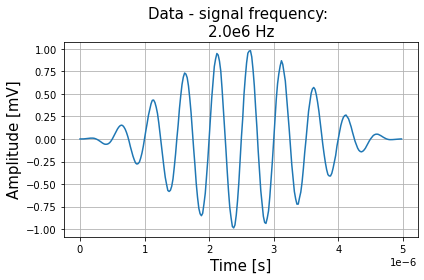

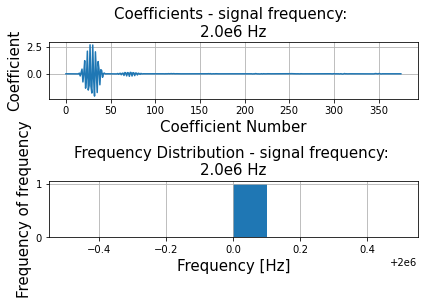

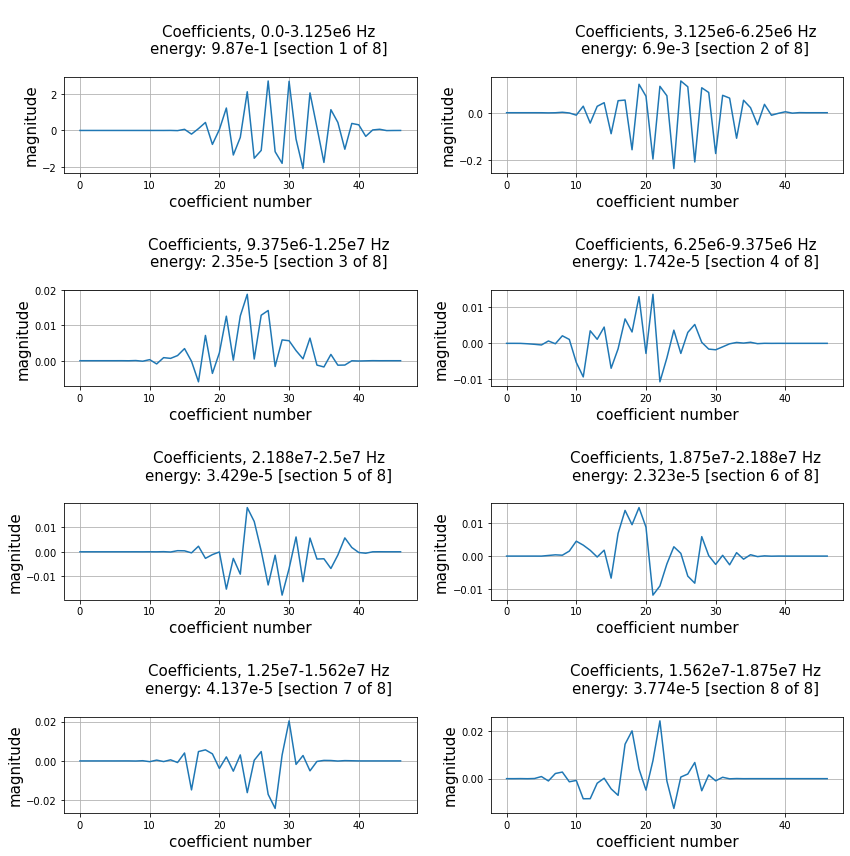

In [1]:
import sys
sys.path.append('..')

from wavelet_transform.test import synthetic_data as sd
from wavelet_transform.wpt import transform as wpt
from wavelet_transform.postprocess import plotting as plot
from wavelet_transform.utils.extensions import sci_form
from wavelet_transform.test import plotting as test_plot

import matplotlib.pyplot as plt
from scipy.signal import hanning

amp_sin_waves = 1 # amplitude of the sine waves added together to form the signal
sampling_rate = 50e6
phase = 0

frequency = 2e6

frequencies = [frequency] # create list of frequencies for synthetic data
time_period = 1/frequency
signal_duration = 10*time_period # duration of the signal is 10 times the test frequency
delay = 0#2*time_period # signal starts 2 time periods late
end = signal_duration#8*time_period # signal ends 2 time periods early

gaussian_noise_std = 0.01 # set the standard devaition of the noise

# generate data
data, t_plot = sd.sound_wave(
    amp_sin_waves, frequencies, phase, signal_duration, 
    sampling_rate, delay, end
    )

# add noise
gaussian_noise = sd.noise(gaussian_noise_std,signal_duration,sampling_rate)
data += gaussian_noise
data = hanning(len(data))*data

# transform parameters
levels = 3
db_order = 10
wavelet = f'db{db_order}'

# transform
transform_object = wpt.dwpt(data,levels, wavelet, 'constant')
final_level_nodes = transform_object.get_level(levels)
dwt_nodes = transform_object.dwt_results() # the dwt results can be extracted from the dwpt

# calculate energy
transform_object.calc_frequencies(sampling_rate)

# set title
f = sci_form(frequency)
title = f"- signal frequency: \n{f} Hz"

# plot everything
plot.full_plot(
    final_level_nodes, data, t_plot, sampling_rate, 
    title, frequencies
    )

## 1.2 Testing with pywt library

pywt result


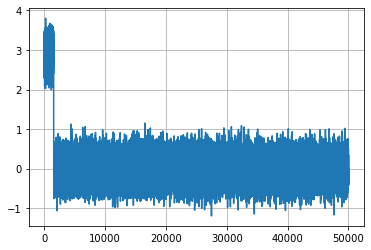

library result


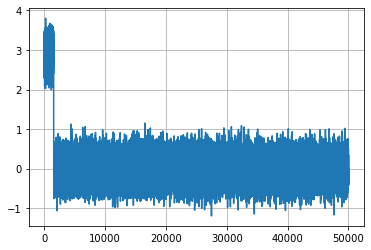

4.343759001842772e-17


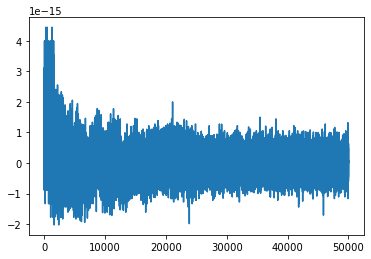

In [7]:
import pywt
import numpy as np
import random
# test result against pywt library
data = [random.random() for _ in range(50000)]
levels = 5
wavelet = "haar"
pywp_object = pywt.WaveletPacket(data, wavelet, maxlevel = levels)
print("pywt result")
pywt_result = test_plot.plot_pywp_test(pywp_object, levels)
print("library result")
obj = wpt.dwpt(data, levels, wavelet)
library_result = test_plot.plot_test(obj.get_level(levels))
error = pywt_result - library_result
print(np.mean(error))
plot.plt.plot(error)

## 1.3 specifying nodes to plot

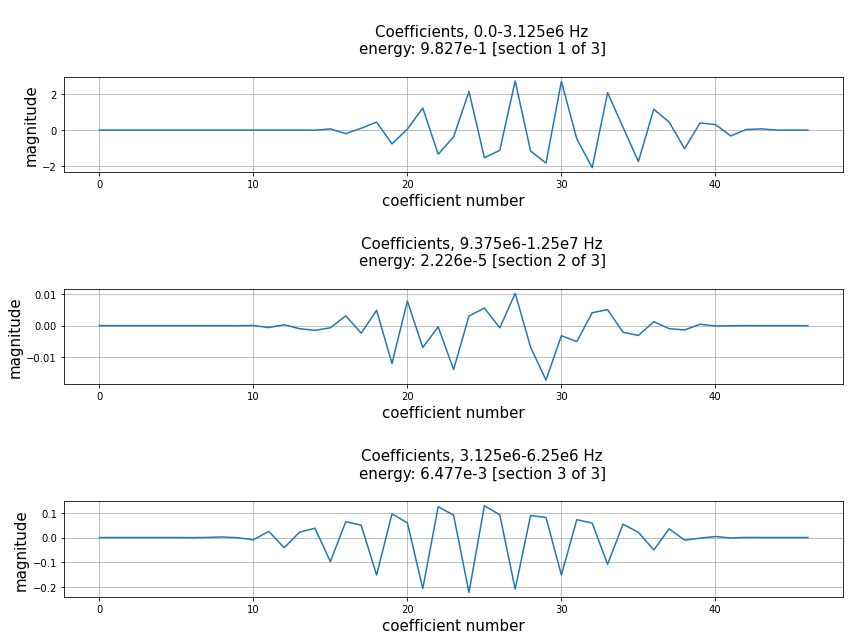

In [4]:
# find nodes with frequencies of interest
frequencies_of_interest = [1e6,1e7,0.5e7]

nodes_of_interest = transform_object.find_nodes(final_level_nodes,frequencies_of_interest)

# plot data from selected nodes
rows = int(len(nodes_of_interest))

fig,ax = plt.subplots(rows)
plot.plot_nodes(nodes_of_interest,ax,sampling_rate,rows,columns = 1)
fig.set_size_inches(12,3*rows)
fig.tight_layout()

## 2.1 Testing inverse transform

In [5]:
import sys
sys.path.append('..')

from wavelet_transform.wpt import inverse_transform as inv
from wavelet_transform.wpt import transform as wpt
import numpy as np
from wavelet_transform.test import synthetic_data as sd

from scipy.signal import blackmanharris
import matplotlib.pyplot as plt

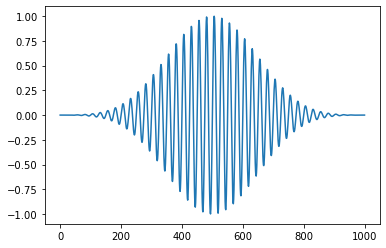

dwt inverse [ 1.78918769e-17  1.50602805e-05  2.99817218e-05 ... -2.99817218e-05
 -4.45513919e-17 -1.65321773e-16]
error dwt [-1.78918769e-17  1.27901975e-17  9.19200154e-18 ... -2.80334024e-17
  4.45513919e-17  1.65321773e-16]
dwpt inverse [ 1.51032327e-17  1.50602805e-05  2.99817218e-05 ... -2.99817218e-05
  9.78492461e-17  9.87026318e-17]
length of dwpt inverse 1001
total error, packet 1.1089505820512454e-14


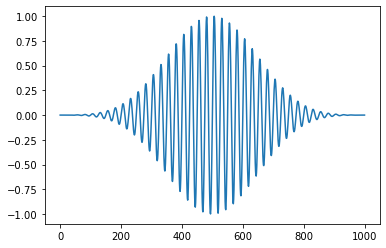

In [6]:
# transform
levels = 8
wavelet = 'db38'
sf = 50e6
freq = 2e6
amp_sin_waves = 1
phase = 0
frequencies = [freq]
signal_duration = 1000/sf
data, t_plot = sd.sound_wave(
    amp_sin_waves, frequencies, phase, signal_duration, 
    sampling_rate=sf
    )
data = data * blackmanharris(len(data))
plt.plot(data)
plt.show()
transform_object = wpt.dwpt(data, levels, wavelet)

# inverse dwt
dwt_inverse = inv.inv_dwt(transform_object)
print('dwt inverse', dwt_inverse)
print('error dwt', data - dwt_inverse)

# inverse dwpt
dwpt_inverse = inv.inv_dwpt(transform_object)
print('dwpt inverse', dwpt_inverse)
print('length of dwpt inverse', len(dwpt_inverse))
print('total error, packet', sum(np.array(data) - dwpt_inverse))
plt.plot(dwpt_inverse)
plt.show()

In [16]:
# testing the reconstruction of separate nodes
rec_1 = inv.inv_dwpt(transform_object, nodes=50)
rec_0 = inv.inv_dwpt(transform_object, nodes=0)
rec_1_0 = inv.inv_dwpt(transform_object, nodes=[0, 50])
error = rec_1_0 - rec_1 - rec_0
print("average error", np.mean(error))

average error -8.030634635246959e-23


## 2.2 Testing inverse transform with synthetic data

The data is generated using the synthetic data package. Nodes are chosen for reconstruction and then the reconstructed sine wave is plotted alongside the transform results.

C:\Users\maxau\AppData\Local\Temp\ipykernel_9128\429192517.py:30: DeprecationWarning: `hanning` is deprecated, use `scipy.signal.windows.hann` instead!
  data = hanning(len(data))*data


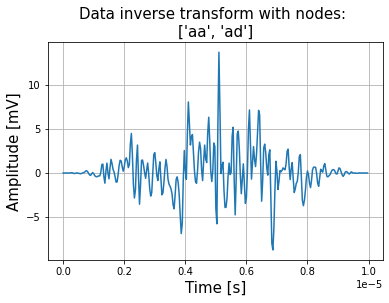

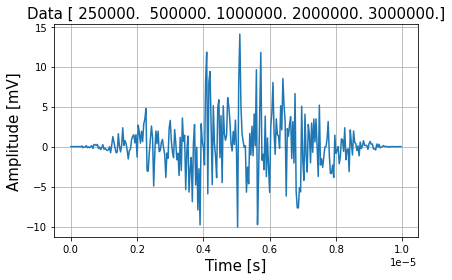

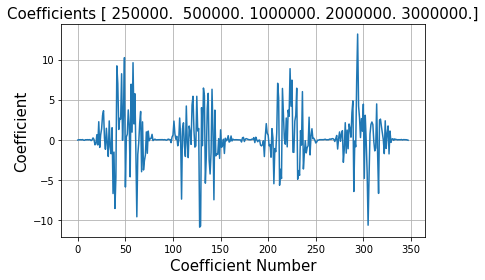

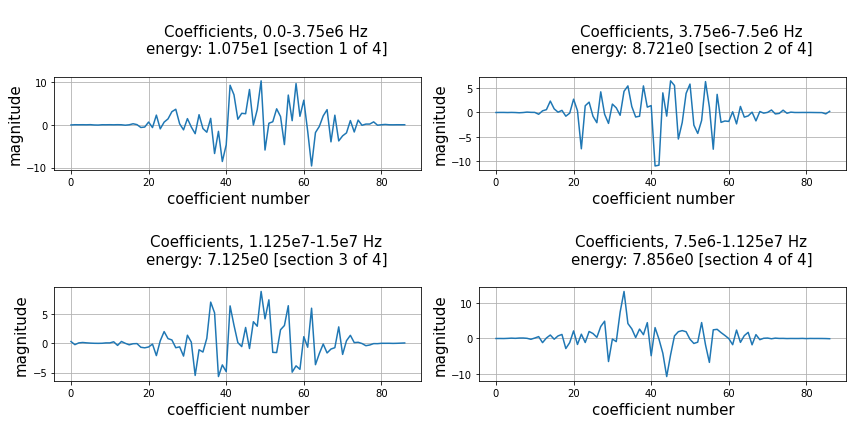

In [8]:
from numpy.random import seed

seed(seed = 1)

# set parameters for synthetic data
amp_sin_waves = 1 # amplitude of each sine wave that is added to the sound wave
sampling_rate = 30e6

test_frequencies = [1e6] # list of frequencies to test
harmonics = [1/4, 1/2, 1, 2, 3] # list of harmonics to test for each frequency

for frequency in test_frequencies:
    frequencies = frequency*np.array(harmonics)

    time_period = 1/frequency
    signal_duration = 10*time_period # signal duration is 10 times the period of the central frequency
    delay = 2*time_period # signal starts 2 time periods late
    end = 8*time_period # signal ends 2 time periods early

    gaussian_noise_std = 5 # set the standard devaition of the noise

    # generate data
    data, t_plot = sd.sound_wave(
        amp_sin_waves, frequencies, phase, signal_duration, 
        sampling_rate, delay, end
        )

    gaussian_noise = sd.noise(gaussian_noise_std, signal_duration, sampling_rate)
    data += gaussian_noise
    data = hanning(len(data))*data

    # set parameters for transform
    levels = 2
    db_order = 9
    wavelet = f'db{db_order}'

    # transform
    transform_object = wpt.dwpt(data,levels,wavelet)
    final_nodes = transform_object.get_level(levels) # collect nodes from the last level
    transform_object.calc_frequencies(sampling_rate) # calculate the frequency ranges for each node

    nodes = ["aa", "ad"]  
    # takes same keyword arguments as packet_nodes_for_rec
    inverse = inv.inv_dwpt(transform_object, nodes=nodes)

    # plot inverse transform
    title = f'inverse transform with nodes: \n{nodes}'
    fig,ax = plt.subplots()
    plot.plot_wave(inverse,t_plot,ax,title)
    plt.show()

    # plot initial wave and transform coefficients
    plot.full_plot(final_nodes,data,t_plot,sampling_rate,frequencies)